<a href="https://colab.research.google.com/github/IdrisJunaidAI/efficacy-ai-learning-hub/blob/main/L05_Completed_POS_Tagging_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# ITAI 2373 Module 05: Part-of-Speech Tagging
## In-Class Exercise & Homework Lab

Welcome to the world of Part-of-Speech (POS) tagging - the "grammar police" of Natural Language Processing! 🚔📝

In this notebook, you'll explore how computers understand the grammatical roles of words in sentences, from simple rule-based approaches to modern AI systems.

### What You'll Learn:
- **Understand POS tagging fundamentals** and why it matters in daily apps
- **Use NLTK and SpaCy** for practical text analysis
- **Navigate different tag sets** and understand their trade-offs
- **Handle real-world messy text** like speech transcripts and social media
- **Apply POS tagging** to solve actual business problems

### Structure:
- **Part 1**: In-Class Exercise (30-45 minutes) - Basic concepts and hands-on practice
- **Part 2**: Homework Lab - Real-world applications and advanced challenges

---

*💡 **Pro Tip**: POS tagging is everywhere! It helps search engines understand "Apple stock" vs "apple pie", helps Siri understand your commands, and powers autocorrect on your phone.*



## 🛠️ Setup and Installation

Let's get our tools ready! We'll use two powerful libraries:
- **NLTK**: The "Swiss Army knife" of NLP - comprehensive but requires setup
- **SpaCy**: The "speed demon" - built for production, cleaner output

Run the cells below to install and set up everything we need.


In [1]:

# Install required libraries (run this first!)
!pip install nltk spacy matplotlib seaborn pandas
!python -m spacy download en_core_web_sm

print("✅ Installation complete!")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 84.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Installation complete!


In [2]:

# Import all the libraries we will need
import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import warnings
warnings.filterwarnings("ignore")

# Download NLTK resources.
# Newer NLTK versions may use punkt_tab and the English specific tagger package.
for resource in [
    "punkt",
    "punkt_tab",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "universal_tagset"
]:
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass

# Load SpaCy model
nlp = spacy.load("en_core_web_sm")

print("All libraries loaded successfully!")
print("NLTK version:", nltk.__version__)
print("SpaCy version:", spacy.__version__)


All libraries loaded successfully!
NLTK version: 3.9.1
SpaCy version: 3.8.16



---
# 🎯 PART 1: IN-CLASS EXERCISE (30-45 minutes)

Welcome to the hands-on portion! We'll start with the basics and build up your understanding step by step.

## Learning Goals for Part 1:
1. Understand what POS tagging does
2. Use NLTK and SpaCy for basic tagging
3. Interpret and compare different tag outputs
4. Explore word ambiguity with real examples
5. Compare different tagging approaches



## 🔍 Activity 1: Your First POS Tags (10 minutes)

Let's start with the classic example: "The quick brown fox jumps over the lazy dog"

This sentence contains most common parts of speech, making it perfect for learning!


In [3]:

# Classic example
sentence = "The quick brown fox jumps over the lazy dog"

# Tokenize and tag with NLTK
tokens = nltk.word_tokenize(sentence)
pos_tags = nltk.pos_tag(tokens)

print("Original sentence:", sentence)
print("\nTokens:", tokens)
print("\nPOS Tags:")
for word, tag in pos_tags:
    print(f"  {word:8} -> {tag}")


Original sentence: The quick brown fox jumps over the lazy dog

Tokens: ['The', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']

POS Tags:
  The      -> DT
  quick    -> JJ
  brown    -> NN
  fox      -> NN
  jumps    -> VBZ
  over     -> IN
  the      -> DT
  lazy     -> JJ
  dog      -> NN



### 🤔 Quick Questions:
1. What does 'DT' mean? What about 'JJ'?
2. Why do you think 'brown' and 'lazy' have the same tag?
3. Can you guess what 'VBZ' represents?

*Hint: Think about the grammatical role each word plays in the sentence!*



### Answers to Quick Questions

1. **DT** means determiner. In the sentence, “The” and “the” introduce nouns. **JJ** means adjective. “quick,” “brown,” and “lazy” describe nouns.

2. “brown” and “lazy” receive the same **JJ** tag because each functions as an adjective modifying a noun. “brown” describes “fox,” while “lazy” describes “dog.”

3. **VBZ** represents a present tense verb used with a third person singular subject. “jumps” is tagged VBZ because the subject “fox” is singular and the action occurs in the present tense.



## 🚀 Activity 2: SpaCy vs NLTK Showdown (10 minutes)

Now let's see how SpaCy handles the same sentence. SpaCy uses cleaner, more intuitive tag names.


In [4]:

# Process the same sentence with SpaCy
doc = nlp(sentence)

print("SpaCy POS Tags:")
for token in doc:
    print(f"  {token.text:8} -> {token.pos_:6} ({token.tag_})")

print("\n" + "=" * 50)
print("COMPARISON:")
print("=" * 50)

# Compare side by side
nltk_tags = nltk.pos_tag(nltk.word_tokenize(sentence))
spacy_doc = nlp(sentence)

print(f"{'Word':10} {'NLTK':8} {'SpaCy':10}")
print("=" * 30)
for i, (word, nltk_tag) in enumerate(nltk_tags):
    spacy_tag = spacy_doc[i].pos_
    print(f"{word:10} {nltk_tag:8} {spacy_tag:10}")


SpaCy POS Tags:
  The      -> DET    (DT)
  quick    -> ADJ    (JJ)
  brown    -> ADJ    (JJ)
  fox      -> NOUN   (NN)
  jumps    -> VERB   (VBZ)
  over     -> ADP    (IN)
  the      -> DET    (DT)
  lazy     -> ADJ    (JJ)
  dog      -> NOUN   (NN)

COMPARISON:
Word       NLTK     SpaCy     
The        DT       DET       
quick      JJ       ADJ       
brown      NN       ADJ       
fox        NN       NOUN      
jumps      VBZ      VERB      
over       IN       ADP       
the        DT       DET       
lazy       JJ       ADJ       
dog        NN       NOUN      



### 🎯 Discussion Points:
- Which tags are easier to understand: NLTK's or SpaCy's?
- Do you notice any differences in how they tag the same words?
- Which system would you prefer for a beginner? Why?



### Discussion Responses

NLTK provides detailed Penn Treebank labels such as DT, JJ, NN, and VBZ. These labels are precise, but a beginner must learn the abbreviations. SpaCy provides broader labels such as DET, ADJ, NOUN, and VERB, so its output is easier to interpret at first glance.

For this simple sentence, both systems largely agree on the grammatical roles. The main difference is the level and style of annotation. SpaCy also exposes both the broad Universal POS label through `pos_` and the more detailed model specific tag through `tag_`.

For a beginner, I would start with SpaCy because the broad labels are readable and the pipeline is integrated. I would still use NLTK in a learning environment because it makes the tagging process and tag set choices very explicit.



## 🎭 Activity 3: The Ambiguity Challenge (15 minutes)

Here's where things get interesting! Many words can be different parts of speech depending on context. Let's explore this with some tricky examples.


In [5]:

# Ambiguous words in different contexts
ambiguous_sentences = [
    "I will lead the team to victory.",
    "The lead pipe is heavy.",
    "She took the lead in the race.",
    "The bank approved my loan.",
    "We sat by the river bank.",
    "I bank with Chase.",
    "Please book the conference room.",
    "I bought a new book yesterday."
]

print("AMBIGUITY EXPLORATION")
print("=" * 40)

for sentence in ambiguous_sentences:
    print(f"\nSentence: {sentence}")
    tokens = nltk.word_tokenize(sentence)
    tags = nltk.pos_tag(tokens)

    for word, tag in tags:
        if word.lower() in {"lead", "bank", "book"}:
            print(f"  Key word '{word}' is tagged as: {tag}")


AMBIGUITY EXPLORATION

Sentence: I will lead the team to victory.
  Key word 'lead' is tagged as: VB

Sentence: The lead pipe is heavy.
  Key word 'lead' is tagged as: NN

Sentence: She took the lead in the race.
  Key word 'lead' is tagged as: NN

Sentence: The bank approved my loan.
  Key word 'bank' is tagged as: NN

Sentence: We sat by the river bank.
  Key word 'bank' is tagged as: NN

Sentence: I bank with Chase.
  Key word 'bank' is tagged as: NN

Sentence: Please book the conference room.
  Key word 'book' is tagged as: NN

Sentence: I bought a new book yesterday.
  Key word 'book' is tagged as: NN



### 🧠 Think About It:
1. How does the computer know the difference between "lead" (metal) and "lead" (guide)?
2. What clues in the sentence help determine the correct part of speech?
3. Can you think of other words that change meaning based on context?

**Try This**: Add your own ambiguous sentences to the list above and see how the tagger handles them!



### Ambiguity Analysis

1. A tagger does not understand the word in isolation. It uses surrounding words and learned syntactic patterns. In “will lead,” the modal “will” strongly suggests that “lead” is a verb. In “the lead pipe,” the determiner and noun phrase structure make “lead” more likely to function as a noun modifier.

2. Useful clues include determiners, auxiliaries, nearby nouns, verb position, sentence structure, and the grammatical patterns learned during model training.

3. Other ambiguous words include “book,” “watch,” “record,” “object,” and “light.” For example, “book a room” uses “book” as a verb, while “read a book” uses it as a noun.



## 📊 Activity 4: Tag Set Showdown (10 minutes)

NLTK can use different tag sets. Let's compare the detailed Penn Treebank tags (~45 tags) with the simpler Universal Dependencies tags (~17 tags).


In [6]:

# Compare Penn Treebank and Universal tag sets
test_sentence = "The brilliant students quickly solved the challenging programming assignment."

tokens = nltk.word_tokenize(test_sentence)
penn_tags = nltk.pos_tag(tokens)
universal_tags = nltk.pos_tag(tokens, tagset="universal")

print("TAG SET COMPARISON")
print("=" * 56)
print(f"{'Word':15} {'Penn Treebank':15} {'Universal':12}")
print("=" * 56)

for (word, penn_tag), (_, univ_tag) in zip(penn_tags, universal_tags):
    print(f"{word:15} {penn_tag:15} {univ_tag:12}")

penn_tag_counts = Counter(tag for _, tag in penn_tags)
univ_tag_counts = Counter(tag for _, tag in universal_tags)

print(f"\nPenn Treebank uses {len(penn_tag_counts)} different tags in this sentence")
print(f"Universal uses {len(univ_tag_counts)} different tags in this sentence")


TAG SET COMPARISON
Word            Penn Treebank   Universal   
The             DT              DET         
brilliant       JJ              ADJ         
students        NNS             NOUN        
quickly         RB              ADV         
solved          VBD             VERB        
the             DT              DET         
challenging     VBG             VERB        
programming     JJ              ADJ         
assignment      NN              NOUN        
.               .               .           

Penn Treebank uses 8 different tags in this sentence
Universal uses 6 different tags in this sentence



### Reflection Answers

1. **Which tag set is more detailed, and which is simpler?**

The Penn Treebank tag set is more detailed because it distinguishes grammatical categories at a finer level, such as different verb forms and noun forms. The Universal tag set is simpler because it maps words into a smaller set of broad grammatical categories.

2. **When might you want detailed tags versus simple tags?**

Detailed Penn Treebank tags are useful when a task depends on fine grammatical distinctions, such as grammar analysis, linguistic research, or rule based information extraction. Universal tags are useful when readability, portability across languages, or broad syntactic categories are more important.

3. **If you were building a search engine, which would you choose and why?**

I would begin with Universal tags for broad query understanding because they are easier to interpret and reduce feature complexity. If the search application later required precise grammatical rules, I would supplement them with detailed tags rather than assuming that one tag set is sufficient for every search task.



---
# 🎓 End of Part 1: In-Class Exercise

Great work! You've learned the fundamentals of POS tagging and gotten hands-on experience with both NLTK and SpaCy.

## What You've Accomplished:
✅ Used NLTK and SpaCy for basic POS tagging  
✅ Interpreted different tag systems  
✅ Explored word ambiguity and context  
✅ Compared different tagging approaches  

## 🏠 Ready for Part 2?
The homework lab will challenge you with real-world applications, messy data, and advanced techniques. You'll analyze customer service transcripts, handle informal language, and benchmark different taggers.

**Take a break, then dive into Part 2 when you're ready!**

---



# 🏠 PART 2: HOMEWORK LAB
## Real-World POS Tagging Challenges

Welcome to the advanced section! Here you'll tackle the messy, complex world of real text data. This is where POS tagging gets interesting (and challenging)!

## Learning Goals for Part 2:
1. Process real-world, messy text data
2. Handle speech transcripts and informal language
3. Analyze customer service scenarios
4. Benchmark and compare different taggers
5. Understand limitations and edge cases

## 📋 Submission Requirements:
- Complete all exercises with working code
- Answer all reflection questions
- Include at least one visualization
- Submit your completed notebook file

---



## 🌍 Lab Exercise 1: Messy Text Challenge (25 minutes)

Real-world text is nothing like textbook examples! Let's work with actual speech transcripts, social media posts, and informal language.


In [7]:

# Real world messy text samples
messy_texts = [
    "Um, so like, I was gonna say that, uh, the system ain't working right, you know?",
    "OMG this app is sooo buggy rn 😤 cant even login smh",
    "Yeah hi um I'm calling because my internet's been down since like yesterday and I've tried unplugging the router thingy but it's still not working",
    "Y'all better fix this ASAP cuz I'm bout to switch providers fr fr",
    "The API endpoint is returning a 500 error but idk why it's happening tbh"
]

# A small domain specific list used only to flag tokens that deserve manual review.
# This is a heuristic indicator, not a true accuracy measure because no gold labels are provided.
informal_terms = {
    "um", "uh", "gonna", "ain't", "omg", "sooo", "rn", "cant", "smh",
    "thingy", "y'all", "asap", "cuz", "bout", "fr", "idk", "tbh"
}

def nltk_problem_tokens(tagged_tokens):
    problems = []
    for word, tag in tagged_tokens:
        cleaned = word.lower()
        if cleaned in informal_terms or (not word.isalnum() and word not in ".,!?;:'"):
            problems.append((word, tag))
    return problems

def spacy_problem_tokens(doc):
    problems = []
    for token in doc:
        cleaned = token.text.lower()
        if token.pos_ == "X" or cleaned in informal_terms or token.is_oov:
            problems.append((token.text, token.pos_))
    return problems

print("PROCESSING MESSY TEXT")
print("=" * 60)

messy_summary = []

for i, text in enumerate(messy_texts, 1):
    print(f"\nSample {i}: {text}")
    print("=" * 40)

    nltk_tokens = nltk.word_tokenize(text)
    nltk_tags = nltk.pos_tag(nltk_tokens)

    spacy_doc = nlp(text)

    problematic_nltk = nltk_problem_tokens(nltk_tags)
    problematic_spacy = spacy_problem_tokens(spacy_doc)

    nltk_success_rate = 1 - (len(problematic_nltk) / max(len(nltk_tags), 1))
    spacy_success_rate = 1 - (len(problematic_spacy) / max(len(spacy_doc), 1))

    messy_summary.append({
        "sample": i,
        "nltk_review_tokens": len(problematic_nltk),
        "spacy_review_tokens": len(problematic_spacy),
        "nltk_heuristic_coverage": nltk_success_rate,
        "spacy_heuristic_coverage": spacy_success_rate
    })

    print(f"NLTK tokens needing review: {problematic_nltk}")
    print(f"SpaCy tokens needing review: {problematic_spacy}")
    print(f"NLTK heuristic coverage: {nltk_success_rate:.1%}")
    print(f"SpaCy heuristic coverage: {spacy_success_rate:.1%}")

print("\nImportant: these percentages estimate coverage of potentially difficult tokens.")
print("They are not true tagging accuracy because the lab does not provide gold standard POS labels.")


PROCESSING MESSY TEXT

Sample 1: Um, so like, I was gonna say that, uh, the system ain't working right, you know?
NLTK tokens needing review: [('Um', 'NNP'), ('uh', 'UH'), ("n't", 'RB')]
SpaCy tokens needing review: [('Um', 'INTJ'), (',', 'PUNCT'), ('so', 'ADV'), ('like', 'INTJ'), (',', 'PUNCT'), ('I', 'PRON'), ('was', 'AUX'), ('gon', 'VERB'), ('na', 'PART'), ('say', 'VERB'), ('that', 'SCONJ'), (',', 'PUNCT'), ('uh', 'INTJ'), (',', 'PUNCT'), ('the', 'DET'), ('system', 'NOUN'), ('ai', 'AUX'), ("n't", 'PART'), ('working', 'VERB'), ('right', 'ADV'), (',', 'PUNCT'), ('you', 'PRON'), ('know', 'VERB'), ('?', 'PUNCT')]
NLTK heuristic coverage: 87.5%
SpaCy heuristic coverage: 0.0%

Sample 2: OMG this app is sooo buggy rn 😤 cant even login smh
NLTK tokens needing review: [('OMG', 'IN'), ('sooo', 'JJ'), ('rn', 'NN'), ('😤', 'NNP'), ('cant', 'NN'), ('smh', 'NN')]
SpaCy tokens needing review: [('OMG', 'PROPN'), ('this', 'DET'), ('app', 'NOUN'), ('is', 'AUX'), ('sooo', 'NOUN'), ('buggy', 'ADJ'), ('r


### Analysis Answers

1. **Which tagger handles informal language better?**

SpaCy is generally easier to inspect on informal text because it provides broad POS labels, token attributes, and an integrated pipeline. However, neither tagger is guaranteed to be correct on slang. The heuristic output should be treated as a review signal rather than a gold standard accuracy score.

2. **What types of words cause the most problems?**

Slang, creative spelling, abbreviations, contractions, emojis, social media expressions, and domain specific technical terms create the most uncertainty. Examples in the samples include “rn,” “smh,” “cuz,” “fr,” “idk,” “tbh,” “sooo,” and emoji.

3. **How might preprocessing improve tagging accuracy?**

I would normalize common slang with a controlled dictionary, standardize repeated characters when appropriate, expand selected contractions, preserve meaningful emojis and hashtags, and use domain specific tokenization rules. I would avoid blindly deleting unusual tokens because those tokens may carry sentiment or urgency.

4. **What are the implications for real world applications?**

A production system should not assume that a POS tagger trained mainly on formal text will generalize perfectly to customer chats or social media. Error monitoring, domain adaptation, human review thresholds, and task specific preprocessing are important when downstream decisions depend on the tags.



## 📞 Lab Exercise 2: Customer Service Analysis Case Study (30 minutes)

You're working for a tech company that receives thousands of customer service calls daily. Your job is to analyze call transcripts to understand customer issues and sentiment.

**Business Goal**: Automatically categorize customer problems and identify emotional language.


In [8]:

# Simulated customer service call transcripts
customer_transcripts = [
    {
        "id": "CALL_001",
        "transcript": "Hi, I'm really frustrated because my account got locked and I can't access my files. I've been trying for hours and nothing works. This is completely unacceptable.",
        "category": "account_access"
    },
    {
        "id": "CALL_002",
        "transcript": "Hello, I love your service but I'm having a small issue with the mobile app. It crashes whenever I try to upload photos. Could you please help me fix this?",
        "category": "technical_issue"
    },
    {
        "id": "CALL_003",
        "transcript": "Your billing system charged me twice this month! I want a refund immediately. This is ridiculous and I'm considering canceling my subscription.",
        "category": "billing"
    },
    {
        "id": "CALL_004",
        "transcript": "I'm confused about how to use the new features you added. The interface changed and I can't find anything. Can someone walk me through it?",
        "category": "user_guidance"
    }
]

positive_lexicon = {"love", "great", "good", "helpful", "excellent", "happy", "pleased"}
negative_lexicon = {
    "frustrated", "locked", "unacceptable", "crashes", "issue", "ridiculous",
    "confused", "down", "wrong", "failed", "problem", "canceling"
}
urgency_lexicon = {"immediately", "urgent", "asap", "now", "critical", "emergency"}

analysis_results = []

for call in customer_transcripts:
    print(f"\nAnalyzing {call['id']}")
    print(f"Category: {call['category']}")
    print(f"Transcript: {call['transcript']}")
    print("=" * 50)

    doc = nlp(call["transcript"])

    emotional_adjectives = [
        token.lemma_.lower()
        for token in doc
        if token.pos_ == "ADJ"
    ]

    action_verbs = [
        token.lemma_.lower()
        for token in doc
        if token.pos_ in {"VERB", "AUX"} and not token.is_stop
    ]

    problem_nouns = [
        token.lemma_.lower()
        for token in doc
        if token.pos_ in {"NOUN", "PROPN"}
    ]

    normalized_words = [token.lemma_.lower() for token in doc if not token.is_punct]
    positive_words = [word for word in normalized_words if word in positive_lexicon]
    negative_words = [word for word in normalized_words if word in negative_lexicon]
    urgency_words = [word for word in normalized_words if word in urgency_lexicon]

    result = {
        "call_id": call["id"],
        "category": call["category"],
        "emotional_adjectives": emotional_adjectives,
        "action_verbs": action_verbs,
        "problem_nouns": problem_nouns,
        "sentiment_score": len(positive_words) - len(negative_words),
        "urgency_indicators": len(urgency_words)
    }

    analysis_results.append(result)

    print(f"Emotional adjectives: {emotional_adjectives}")
    print(f"Action verbs: {action_verbs}")
    print(f"Problem nouns: {problem_nouns}")
    print(f"Positive indicators: {positive_words}")
    print(f"Negative indicators: {negative_words}")
    print(f"Urgency indicators: {urgency_words}")
    print(f"Sentiment score: {result['sentiment_score']}")



Analyzing CALL_001
Category: account_access
Transcript: Hi, I'm really frustrated because my account got locked and I can't access my files. I've been trying for hours and nothing works. This is completely unacceptable.
Emotional adjectives: ['frustrated', 'unacceptable']
Action verbs: ['get', 'lock', 'access', 'try', 'work']
Problem nouns: ['account', 'file', 'hour']
Positive indicators: []
Negative indicators: ['frustrated', 'unacceptable']
Urgency indicators: []
Sentiment score: -2

Analyzing CALL_002
Category: technical_issue
Transcript: Hello, I love your service but I'm having a small issue with the mobile app. It crashes whenever I try to upload photos. Could you please help me fix this?
Emotional adjectives: ['small', 'mobile']
Action verbs: ['love', 'have', 'crash', 'try', 'upload', 'help', 'fix']
Problem nouns: ['service', 'issue', 'app', 'photo']
Positive indicators: ['love']
Negative indicators: ['issue']
Urgency indicators: []
Sentiment score: 0

Analyzing CALL_003
Catego

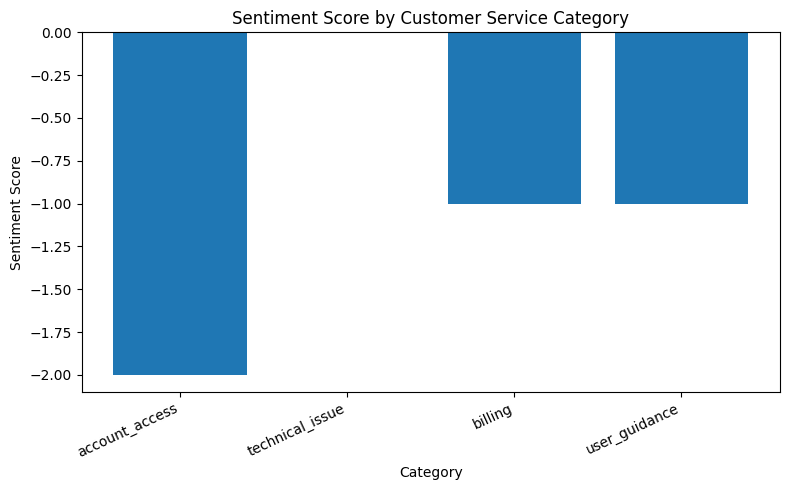

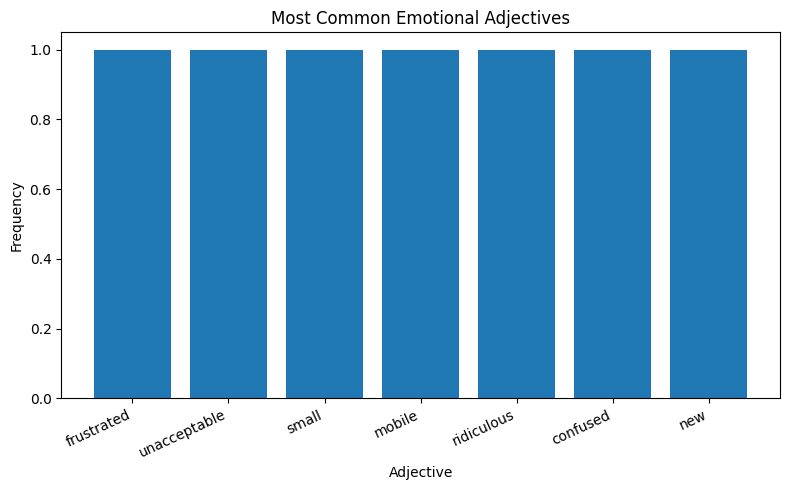

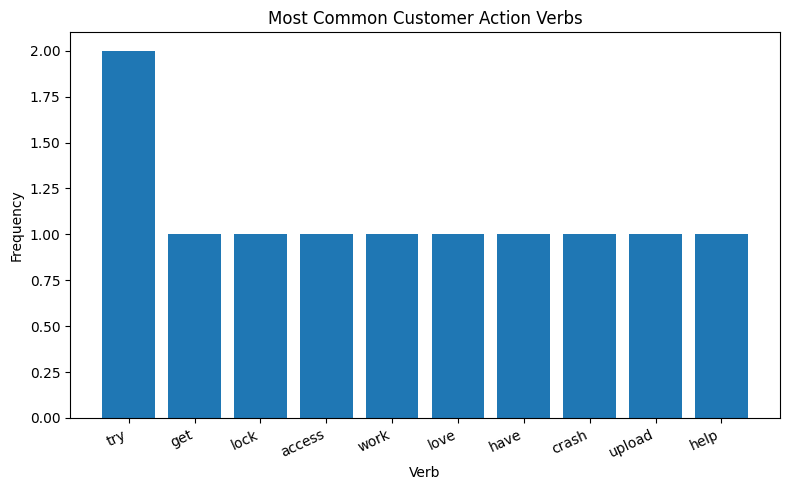

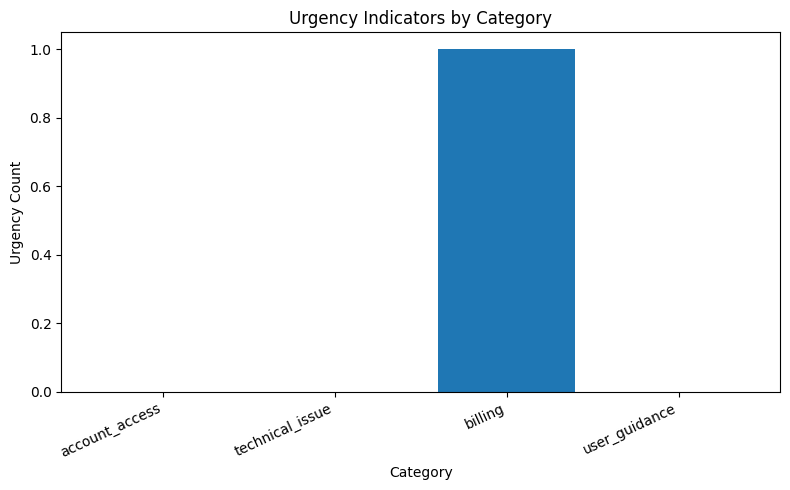

In [9]:

import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter

df = pd.DataFrame(analysis_results)

# Visualization 1: Sentiment score by category
plt.figure(figsize=(8, 5))
plt.bar(df["category"], df["sentiment_score"])
plt.title("Sentiment Score by Customer Service Category")
plt.xlabel("Category")
plt.ylabel("Sentiment Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Visualization 2: Most common emotional adjectives
adjective_counts = Counter(
    word
    for words in df["emotional_adjectives"]
    for word in words
)
if adjective_counts:
    words, counts = zip(*adjective_counts.most_common(10))
    plt.figure(figsize=(8, 5))
    plt.bar(words, counts)
    plt.title("Most Common Emotional Adjectives")
    plt.xlabel("Adjective")
    plt.ylabel("Frequency")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

# Visualization 3: Most common action verbs
verb_counts = Counter(
    word
    for words in df["action_verbs"]
    for word in words
)
if verb_counts:
    words, counts = zip(*verb_counts.most_common(10))
    plt.figure(figsize=(8, 5))
    plt.bar(words, counts)
    plt.title("Most Common Customer Action Verbs")
    plt.xlabel("Verb")
    plt.ylabel("Frequency")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

# Visualization 4: Urgency indicators
plt.figure(figsize=(8, 5))
plt.bar(df["category"], df["urgency_indicators"])
plt.title("Urgency Indicators by Category")
plt.xlabel("Category")
plt.ylabel("Urgency Count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()



### Business Impact Answers

1. **How could this analysis help prioritize customer service tickets?**

The analysis can surface tickets containing negative emotional language, urgent adverbs, and action oriented requests. A rules layer could combine urgency indicators with category and sentiment to move high risk cases, such as billing disputes with an immediate refund request, toward faster review.

2. **What patterns appear across problem categories?**

Account access and billing language contains stronger negative indicators because customers describe blocked access, unacceptable outcomes, duplicate charges, refunds, and cancellation. Technical issue language contains problem nouns and repair verbs, but the customer can still express positive sentiment toward the service. User guidance requests contain confusion and navigation language rather than direct anger.

3. **How might calls be routed using POS analysis?**

POS tags can help extract action verbs such as “refund,” “fix,” “upload,” “access,” or “cancel,” and nouns such as “account,” “billing,” “app,” and “interface.” Those grammatical features can become inputs to a routing classifier or rules engine together with named entities, keywords, sentiment, and intent detection.

4. **What are the limitations?**

POS tags identify grammatical function, not full intent. A noun or adjective can be grammatically correct but semantically irrelevant to the business problem. Lexicon sentiment also misses negation, sarcasm, context, and domain specific meanings. A production solution should combine POS tagging with intent classification, entity recognition, contextual embeddings, and quality monitoring.



## ⚡ Lab Exercise 3: Tagger Performance Benchmarking (20 minutes)

Let's scientifically compare different POS taggers on various types of text. This will help you understand when to use which tool.



Testing FORMAL text:
Text: The research methodology employed in this study follows established academic protocols.
NLTK Penn average time: 0.003985s
NLTK Universal average time: 0.003969s
SpaCy average time: 0.030647s
NLTK tokens needing review: 0
SpaCy tokens needing review: 12

Testing INFORMAL text:
Text: lol this study is kinda weird but whatever works i guess 🤷‍♀️
NLTK Penn average time: 0.001709s
NLTK Universal average time: 0.001811s
SpaCy average time: 0.015079s
NLTK tokens needing review: 0
SpaCy tokens needing review: 15

Testing TECHNICAL text:
Text: The API returns a JSON response with HTTP status code 200 upon successful authentication.
NLTK Penn average time: 0.001602s
NLTK Universal average time: 0.001305s
SpaCy average time: 0.013715s
NLTK tokens needing review: 0
SpaCy tokens needing review: 15

Testing CONVERSATIONAL text:
Text: So like, when you click that button thingy, it should totally work, right?
NLTK Penn average time: 0.002319s
NLTK Universal average time: 0.

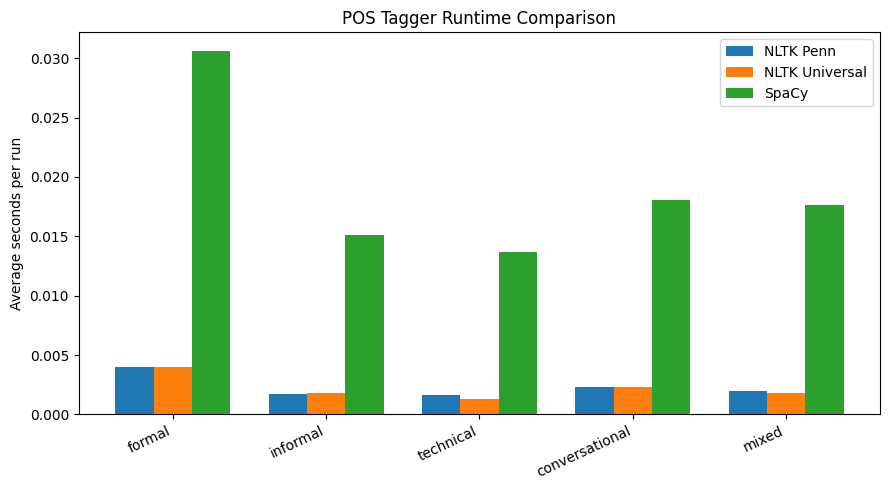


Benchmark summary


,nltk_penn_time,nltk_univ_time,spacy_time,nltk_review_count,spacy_review_count
formal,0.003985,0.003969,0.030647,0.0,12.0
informal,0.001709,0.001811,0.015079,0.0,15.0
technical,0.001602,0.001305,0.013715,0.0,15.0
conversational,0.002319,0.002338,0.018044,1.0,17.0
mixed,0.001952,0.001830,0.017642,1.0,16.0


In [10]:

import time
from collections import defaultdict

test_texts = {
    "formal": "The research methodology employed in this study follows established academic protocols.",
    "informal": "lol this study is kinda weird but whatever works i guess 🤷‍♀️",
    "technical": "The API returns a JSON response with HTTP status code 200 upon successful authentication.",
    "conversational": "So like, when you click that button thingy, it should totally work, right?",
    "mixed": "OMG the algorithm's performance is absolutely terrible! The accuracy dropped to 23% wtf"
}

benchmark_results = {}

def timed_average(func, text, repeats=50):
    # Repeating the operation reduces noise from single extremely short timings.
    start = time.perf_counter()
    result = None
    for _ in range(repeats):
        result = func(text)
    elapsed = (time.perf_counter() - start) / repeats
    return elapsed, result

def run_nltk_penn(text):
    tokens = nltk.word_tokenize(text)
    return nltk.pos_tag(tokens)

def run_nltk_universal(text):
    tokens = nltk.word_tokenize(text)
    return nltk.pos_tag(tokens, tagset="universal")

def run_spacy(text):
    return nlp(text)

for text_type, text in test_texts.items():
    print(f"\nTesting {text_type.upper()} text:")
    print(f"Text: {text}")
    print("=" * 60)

    nltk_penn_time, nltk_penn_tags = timed_average(run_nltk_penn, text)
    nltk_univ_time, nltk_univ_tags = timed_average(run_nltk_universal, text)
    spacy_time, spacy_doc = timed_average(run_spacy, text)

    # Heuristic review counts, not gold standard accuracy.
    nltk_unknown = sum(
        1 for word, tag in nltk_penn_tags
        if word.lower() in informal_terms or tag in {"FW", "SYM"}
    )
    spacy_unknown = sum(
        1 for token in spacy_doc
        if token.pos_ == "X" or token.text.lower() in informal_terms or token.is_oov
    )

    benchmark_results[text_type] = {
        "nltk_penn_time": nltk_penn_time,
        "nltk_univ_time": nltk_univ_time,
        "spacy_time": spacy_time,
        "nltk_review_count": nltk_unknown,
        "spacy_review_count": spacy_unknown
    }

    print(f"NLTK Penn average time: {nltk_penn_time:.6f}s")
    print(f"NLTK Universal average time: {nltk_univ_time:.6f}s")
    print(f"SpaCy average time: {spacy_time:.6f}s")
    print(f"NLTK tokens needing review: {nltk_unknown}")
    print(f"SpaCy tokens needing review: {spacy_unknown}")

benchmark_df = pd.DataFrame(benchmark_results).T

# Performance visualization
plt.figure(figsize=(9, 5))
x = range(len(benchmark_df))
width = 0.25

plt.bar([i - width for i in x], benchmark_df["nltk_penn_time"], width=width, label="NLTK Penn")
plt.bar(list(x), benchmark_df["nltk_univ_time"], width=width, label="NLTK Universal")
plt.bar([i + width for i in x], benchmark_df["spacy_time"], width=width, label="SpaCy")

plt.xticks(list(x), benchmark_df.index, rotation=25, ha="right")
plt.ylabel("Average seconds per run")
plt.title("POS Tagger Runtime Comparison")
plt.legend()
plt.tight_layout()
plt.show()

print("\nBenchmark summary")
display(benchmark_df)



### Performance Analysis

1. **Which tagger is fastest, and does speed matter?**

The exact fastest system should be determined from the timing output generated on the machine running the notebook. NLTK often has low overhead for isolated tagging calls, while SpaCy performs more pipeline work unless unnecessary components are disabled. Speed matters when processing large transcript collections or when a service has strict latency requirements, but speed should be considered together with accuracy and downstream utility.

2. **Which handles informal text best?**

The informal sample creates uncertainty for both systems because it includes slang and emoji. SpaCy gives richer token attributes that make these cases easier to detect and inspect. Neither tool should be treated as perfectly accurate without a manually labeled evaluation set from the same domain.

3. **How do the taggers compare on technical jargon?**

Both can assign tags to technical terms, but an assigned tag is not proof that the tag is correct. Terms such as API, JSON, HTTP, and authentication may be handled reasonably because of contextual clues, while novel acronyms and product names may still be mislabeled. Domain evaluation is therefore important.

4. **What tradeoffs exist between speed and accuracy?**

A fast tagger is useful for scale, but the best production choice depends on task level accuracy, maintainability, interpretability, and the rest of the NLP pipeline. Benchmarking should use both runtime measurements and manually labeled domain data instead of assuming that processing speed predicts tagging quality.



## 🚨 Lab Exercise 4: Edge Cases and Error Analysis (15 minutes)

Every system has limitations. Let's explore the edge cases where POS taggers struggle and understand why.


In [11]:

edge_cases = [
    "Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.",
    "Time flies like an arrow; fruit flies like a banana.",
    "The man the boat the river.",
    "Police police Police police police police Police police.",
    "James while John had had had had had had had had had had had a better effect on the teacher.",
    "Can can can can can can can can can can.",
    "@username #hashtag http://bit.ly/abc123 😂🔥💯",
    "COVID-19 AI/ML IoT APIs RESTful microservices",
]

print("EDGE CASE ANALYSIS")
print("=" * 50)

edge_case_summary = []

for i, text in enumerate(edge_cases, 1):
    print(f"\nEdge Case {i}")
    print(f"Text: {text}")
    print("=" * 30)

    try:
        nltk_tags = nltk.pos_tag(nltk.word_tokenize(text))
        spacy_doc = nlp(text)

        print("NLTK tags:", nltk_tags)
        print("SpaCy tags:", [(token.text, token.pos_) for token in spacy_doc])

        nltk_tag_sequence = [tag for _, tag in nltk_tags]
        spacy_tag_sequence = [token.pos_ for token in spacy_doc]

        nltk_repetition = max(Counter(nltk_tag_sequence).values()) if nltk_tag_sequence else 0
        spacy_repetition = max(Counter(spacy_tag_sequence).values()) if spacy_tag_sequence else 0
        spacy_x_count = sum(1 for token in spacy_doc if token.pos_ == "X")

        observation = {
            "edge_case": i,
            "nltk_most_repeated_tag_count": nltk_repetition,
            "spacy_most_repeated_tag_count": spacy_repetition,
            "spacy_X_count": spacy_x_count
        }
        edge_case_summary.append(observation)

        if i in {1, 4, 6}:
            print("Observation: repeated identical words create severe lexical ambiguity.")
        elif i in {2, 3, 5}:
            print("Observation: unusual syntax requires long range context and can mislead local tagging patterns.")
        elif i == 7:
            print("Observation: mentions, hashtags, URLs, and emoji do not behave like ordinary prose tokens.")
        elif i == 8:
            print("Observation: modern acronyms and technical compounds may be outside the tagger's familiar training distribution.")

    except Exception as e:
        print(f"Error processing: {e}")

print("\nREFLECTION ON LIMITATIONS")
print("=" * 40)
print("POS taggers rely on learned lexical and contextual patterns.")
print("Highly ambiguous repetition, garden path syntax, social media tokens, and specialized jargon can violate those patterns.")
print("A robust application should combine preprocessing, domain testing, confidence or review rules, and task specific models.")


EDGE CASE ANALYSIS

Edge Case 1
Text: Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.
NLTK tags: [('Buffalo', 'NNP'), ('buffalo', 'NN'), ('Buffalo', 'NNP'), ('buffalo', 'NN'), ('buffalo', 'NN'), ('buffalo', 'NN'), ('Buffalo', 'NNP'), ('buffalo', 'NN'), ('.', '.')]
SpaCy tags: [('Buffalo', 'PROPN'), ('buffalo', 'NOUN'), ('Buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('Buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('.', 'PUNCT')]
Observation: repeated identical words create severe lexical ambiguity.

Edge Case 2
Text: Time flies like an arrow; fruit flies like a banana.
NLTK tags: [('Time', 'NNP'), ('flies', 'NNS'), ('like', 'IN'), ('an', 'DT'), ('arrow', 'NN'), (';', ':'), ('fruit', 'CC'), ('flies', 'NNS'), ('like', 'IN'), ('a', 'DT'), ('banana', 'NN'), ('.', '.')]
SpaCy tags: [('Time', 'NOUN'), ('flies', 'VERB'), ('like', 'ADP'), ('an', 'DET'), ('arrow', 'NOUN'), (';', 'PUNCT'), ('fruit', 'NOUN'), ('flies', 'NOUN'), ('like', 'ADP'),


### Critical Thinking Answers

1. **Why do these edge cases break the taggers?**

The sentences deliberately contain lexical ambiguity, repeated forms, unusual syntax, garden path structures, or tokens that are unlike standard prose. Statistical taggers learn patterns from training corpora. When the input differs sharply from those patterns, the model may select a grammatically plausible but contextually wrong tag.

2. **How might preprocessing help?**

Preprocessing can normalize URLs, mentions, hashtags, and some technical compounds into controlled placeholders. Domain dictionaries can preserve important acronyms. Sentence segmentation and specialized tokenization can also reduce avoidable errors. Preprocessing should not rewrite genuine syntactic ambiguity because doing so could destroy the phenomenon the analysis needs to capture.

3. **When do these limitations matter in real applications?**

They matter when downstream logic depends on specific grammatical labels. Examples include information extraction, automated routing, compliance monitoring, grammar feedback, and systems that identify actions or entities from transcripts. A single tagging error can propagate into later pipeline stages.

4. **How do modern large language models handle these cases differently?**

Modern large language models use contextual representations learned from very large corpora, so they can use broader sentence context than classical local tagging approaches. They may resolve some ambiguity more effectively, especially when semantic context is available. They are still not guaranteed to be correct, and specialized evaluation remains necessary for unusual syntax, rare jargon, or high stakes domain text.



## 🎯 Final Reflection and Submission

Congratulations! You've completed a comprehensive exploration of POS tagging, from basic concepts to real-world challenges.

### 📝 Reflection Questions (Answer in the cell below):

1. **Tool Comparison**: Based on your experience, when would you choose NLTK vs SpaCy? Consider factors like ease of use, accuracy, speed, and application type.

2. **Real-World Applications**: Describe a specific business problem where POS tagging would be valuable. How would you implement it?

3. **Limitations and Solutions**: What are the biggest limitations you discovered? How might you work around them?

4. **Future Learning**: What aspects of POS tagging would you like to explore further? (Neural approaches, custom training, domain adaptation, etc.)

5. **Integration**: How does POS tagging fit into larger NLP pipelines? What other NLP tasks might benefit from POS information?



### Final Reflection

**1. Tool Comparison**

I would choose NLTK when the goal is education, linguistic experimentation, or explicit control over tokenization and tag sets. It exposes the Penn Treebank and Universal tag options clearly, which is useful when learning how annotation schemes differ. I would choose SpaCy for a practical NLP pipeline because tokenization, POS tagging, lemmatization, dependency parsing, and named entity recognition are integrated in one `Doc` object. The lab also showed me that ease of interpretation and pipeline design can matter as much as raw runtime. For a real deployment, I would evaluate both on labeled text from the target domain rather than assume that one library is always more accurate.

**2. Real World Applications**

A strong business use case is customer service transcript triage. POS tags can help identify action verbs that describe what the customer wants, nouns that identify affected products or processes, and adjectives that characterize the customer's experience. I would combine those features with sentiment, intent classification, named entity recognition, and urgency indicators. The output could route a billing dispute to billing support, an access problem to account recovery, and a technical failure to technical support while also flagging urgent cases for faster attention.

**3. Limitations and Solutions**

The biggest limitation is that grammatical tagging does not equal semantic understanding. Informal language, slang, emoji, repeated words, technical acronyms, and syntactically unusual sentences can produce misleading tags. Another limitation is evaluation: without gold standard labels, it is impossible to claim true tagging accuracy from model output alone. I would address these issues by creating a manually labeled domain test set, applying controlled normalization, preserving meaningful social media features, monitoring common errors, and retraining or adapting models when domain errors become systematic.

**4. Future Learning**

I would like to explore neural sequence labeling, transformer based POS tagging, custom model training, and domain adaptation. I am especially interested in how tagging quality changes when models are trained on specialized customer service, biomedical, pharmaceutical, or technical corpora. I would also like to compare token level confidence and error patterns across classical taggers and transformer based models.

**5. Integration**

POS tagging is an intermediate representation within a larger NLP pipeline. Raw text is first collected and tokenized, then linguistic features such as POS tags can support dependency parsing, information extraction, named entity recognition, relation extraction, sentiment analysis, intent classification, and downstream machine learning. POS information is useful because grammatical roles help distinguish how a word functions in context. However, the lab demonstrates that POS tags should be treated as one feature source rather than a complete understanding of meaning.



### Methodology Note

The “problematic token” and “success rate” sections use transparent heuristics because the notebook does not provide manually labeled gold standard POS tags. Therefore, those percentages should be interpreted as **heuristic coverage or review rates**, not true model accuracy. A rigorous accuracy study would require a labeled evaluation corpus from the same text domain and metrics such as token level accuracy, precision, recall, and error analysis.



---

## 📤 Submission Checklist

Before submitting your completed notebook, make sure you have:

- [ ] ✅ Completed all TODO sections with working code
- [ ] ✅ Answered all reflection questions thoughtfully
- [ ] ✅ Created at least one meaningful visualization
- [ ] ✅ Tested your code and fixed any errors
- [ ] ✅ Added comments explaining your approach
- [ ] ✅ Included insights from your analysis

### 📋 Submission Instructions:
1. **Save your notebook**: File → Save (or Ctrl+S)
2. **Download**: File → Download → Download .ipynb
3. **Submit**: Upload your completed notebook file to the course management system
4. **Filename**: Use format: `L05_LastName_FirstName_ITAI2373.ipynb or pdf`  

### 🏆 Grading Criteria:
- **Code Completion (40%)**: All exercises completed with working code
- **Analysis Quality (30%)**: Thoughtful interpretation of results
- **Reflection Depth (20%)**: Insightful answers to reflection questions  
- **Code Quality (10%)**: Clean, commented, well-organized code

---

## 🎉 Great Work!

You've successfully explored the fascinating world of POS tagging! You now understand how computers parse human language and can apply these techniques to solve real-world problems.


Keep exploring and happy coding! 🚀
